# Importing Libraries

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KNeighborsClassifier


warnings.filterwarnings('ignore')

# Reading Data

In [5]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1053\\Data\\Code Dataset\\Target_Lesion_Dataset.csv")

In [6]:
df['LSSLD_Change'].unique()

array([0, 1], dtype=int64)

In [7]:
df.columns

Index(['Unnamed: 0', 'SUBJID', 'AGE', 'SEXCD', 'TRTDOSE', 'TRTFREQ', 'TRT',
       'ACHEMO', 'ACHEMMCD', 'FCHEMOCD', 'B_LESNM', 'B_LESNMT', 'B_LESNMN',
       'B_METANM', 'PFSCR', 'INFREAC', 'BAWDOSE', 'OXCWDOSE', 'OXAWDOSE',
       'IRCDOSE', 'IRCWDOSE', 'FBCDOSE', 'FBCWDOSE', 'FICDOSE', 'FICWDOSE',
       'DUREXP', 'IRDSINTR', 'FBDURWK', 'FBDSINT', 'TRTDUR', 'CHANY5YR_N',
       'CHANY5YR_Y', 'CHREGPT_FLUOROURACIL', 'CHREGPT_FOLINIC ACID',
       'CHREGCLS_DETOXIFYING AGENTS FOR ANTINEOPLASTIC TREATMENT',
       'CHREGCLS_PYRIMIDINE ANALOGUES', 'DTHDY', 'DTCAUS', 'BIOPSITP',
       'BIOPTISB', 'BIOPTISS', 'BIOPSITP.1', 'BIOPSITM', 'ICSIGN', 'LDOSDSDY',
       'EOIP', 'EOTA', 'DSDOSDY', 'DSEOSYN', 'DSEOS', 'EOIPDY', 'EOBDY',
       'EOXIRDY', 'EOLEUDY', 'QTY', 'DOSE', 'ACTTRT_5-Fluorouracil',
       'ACTTRT_5-Fluorouracil 22 hour', 'ACTTRT_5-Fluorouracil 46 hour',
       'ACTTRT_5-Fluorouracil bolus', 'ACTTRT_Bevacizumab',
       'ACTTRT_Irinotecan', 'ACTTRT_Leucovorin', 'ACTTRT_Oxali

In [8]:
df.shape

(1791, 89)

In [9]:
df.head()

,Unnamed: 0,SUBJID,AGE,SEXCD,TRTDOSE,TRTFREQ,TRT,ACHEMO,ACHEMMCD,FCHEMOCD,...,SXANY5YR_N,SXANY5YR_Y,SXTYPE_Biopsy,SXTYPE_Laparoscopic,SXTYPE_Open,SXTYPE_Other,SXTYPE_Resection,SXTYPE_Surgery,VSSTRES,VSBLRES
0,8,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
1,9,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
2,10,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
3,11,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
4,20,249101002,72.0,M,0.0,Every 2 weeks,bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,1,0,0,1,1,1,88.514607,90.289888


In [10]:
if((df['LSSLD_Change'].any())==0):
    print(df['SUBJID'])

# Feature Selection by Random Forest

In [12]:
df1=df

In [13]:
df1 = pd.get_dummies(df1, drop_first=True)

In [14]:
# Separate features and target
X = df1.drop('LSSLD_Change', axis=1)
y = df1['LSSLD_Change']

In [15]:
# Train a Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [16]:
importances = rf.feature_importances_

In [24]:
# Create a dataframe for feature importances
feature_importances_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

In [30]:
feature_importances_df.head(50)

,Feature,Importance
56,Percentage_LSSLD_Change,0.354039
55,LSSLD_Diff,0.101483
0,Unnamed: 0,0.062149
54,LSSLD,0.055303
53,DOSREFDY,0.030222
68,VSSTRES,0.026874
21,IRDSINTR,0.021576
16,FBCDOSE,0.017825
33,DSDOSDY,0.016977
35,EOBDY,0.015530


# Forming New Datasets

In [34]:
df=df[['SUBJID','LSNEWANY','LSSLD_Change','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
df.shape

(1791, 27)

In [36]:
df.head()

,SUBJID,LSNEWANY,LSSLD_Change,PFSCR,TRTDUR,OXAWDOSE,EOBDY,OXCWDOSE,LBORRESN,LDOSDSDY,...,FBCDOSE,VSBLRES,FICWDOSE,DOSE,EOXIRDY,B_LESNM,B_LESNMN,B_LESNMT,IRCDOSE,IRDSINTR
0,249101001,N,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
1,249101001,N,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
2,249101001,Y,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
3,249101001,Y,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
4,249101002,N,0,1.0,365.0,90.790640,365.0,907.906402,53.946474,365.0,...,9200.0,90.289888,24059.109235,708.743802,197.0,101.0,99.0,2.0,NaN,NaN


In [38]:
dfnew=df.drop_duplicates(keep='first')
dfnew.shape

(1090, 27)

In [40]:
result1=dfnew

# Logistic Regression

In [43]:
result1.shape

(1090, 27)

In [45]:
result1.fillna(0, inplace=True)

In [47]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [49]:
X=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSSLD_Change']]

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [55]:
model11= LogisticRegression()

In [57]:
result1['LSSLD_Change'].unique()

array([0, 1], dtype=int64)

In [59]:
model11.fit(X_train_scaled, y_train)

LogisticRegression()

In [61]:
y_pred = model11.predict(X_test_scaled)

In [63]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9954


In [65]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[217   0]
 [  1   0]]


In [67]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       217
           1       0.00      0.00      0.00         1

    accuracy                           1.00       218
   macro avg       0.50      0.50      0.50       218
weighted avg       0.99      1.00      0.99       218



In [71]:
y_train_pred = model11.predict(X_train_scaled)

y_test_pred = model11.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.9897
Test Accuracy: 0.9954


# Feature Importance

     Feature  Importance
1      PFSCR    0.777622
3   OXAWDOSE   -0.710760
2     TRTDUR   -0.572381
8   LBSTRESN   -0.501058
16   IRCDOSE    0.489544
5   LBORRESN   -0.423820
13  FICWDOSE   -0.410679
15  B_LESNMT   -0.357956
0   LSNEWANY    0.323348
12   VSBLRES    0.280464
11   FBCDOSE    0.257232
9    FICDOSE    0.256901
10   BAWDOSE   -0.236373
4   OXCWDOSE    0.230820
6    FBDSINT    0.107493
17  IRDSINTR   -0.097114
7   FBCWDOSE    0.030248
14      DOSE   -0.004314


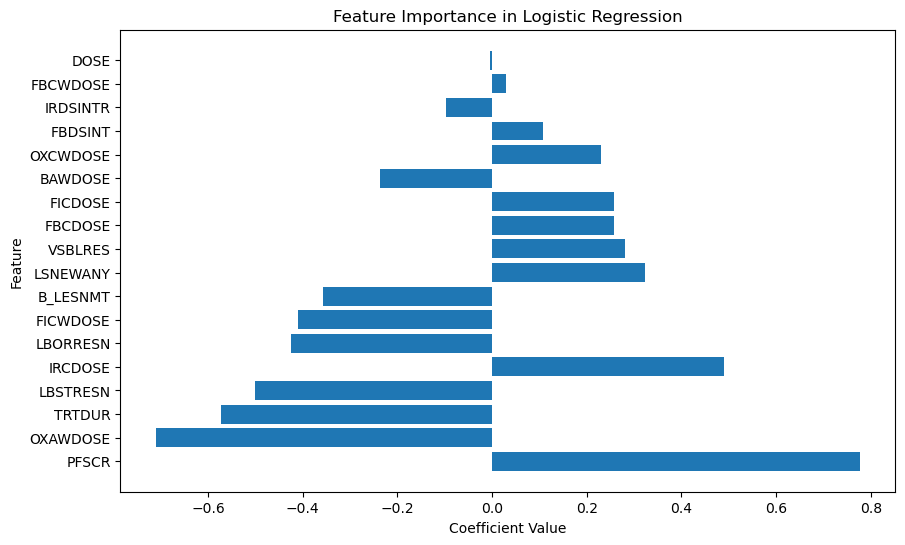

In [73]:
if len(model11.coef_) == 1:
    coefficients = model11.coef_[0]
else:
    coefficients = np.mean(model11.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Hyperparameter Tuning

In [76]:
X=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSSLD_Change']]

In [78]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [80]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model13 = LogisticRegression(solver='liblinear')

In [82]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model13 = LogisticRegression()

In [84]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], 
    'penalty': ['l1', 'l2']  
}

In [86]:
grid_search = GridSearchCV(estimator=model13, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_

In [87]:
best_model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.001)

In [90]:
y_test_pred = best_model.predict(X_test_scaled)

# Evaluate the best model on test data
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.9954

Confusion Matrix on Test Data:
[[217   0]
 [  1   0]]

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       217
           1       0.00      0.00      0.00         1

    accuracy                           1.00       218
   macro avg       0.50      0.50      0.50       218
weighted avg       0.99      1.00      0.99       218



# Feature Importance

     Feature  Importance
16   IRCDOSE    0.009936
3   OXAWDOSE   -0.008846
17  IRDSINTR    0.008453
4   OXCWDOSE   -0.005150
0   LSNEWANY    0.004994
1      PFSCR    0.004599
11   FBCDOSE    0.003271
15  B_LESNMT   -0.002860
9    FICDOSE    0.002810
7   FBCWDOSE    0.002460
14      DOSE    0.002163
8   LBSTRESN   -0.001949
5   LBORRESN   -0.001913
12   VSBLRES    0.001759
13  FICWDOSE    0.001517
10   BAWDOSE   -0.000896
2     TRTDUR    0.000645
6    FBDSINT    0.000593


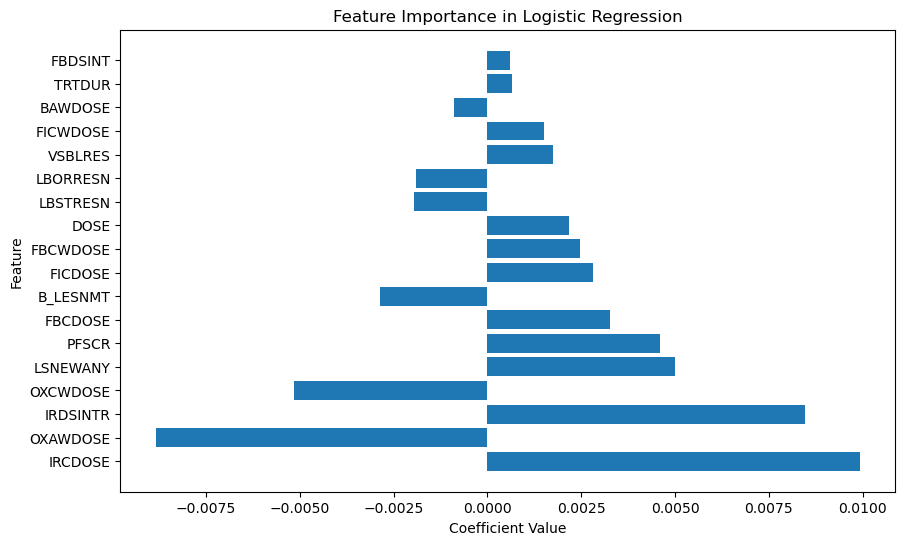

In [92]:
if len(best_model.coef_) == 1:
    coefficients = best_model.coef_[0]
else:
    coefficients = np.mean(best_model.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Elastic Net

In [95]:
X=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSSLD_Change']]

In [97]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
param_grid = {
    'penalty': ['elasticnet'],
    'solver': ['saga'],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9],  
    'C': [0.1, 1.0, 10.0]  
}

In [99]:
model14 = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=10, scoring='accuracy')

In [101]:
model14.fit(X_train_scaled, y_train)

GridSearchCV(cv=10, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.1, 1.0, 10.0],
                         'l1_ratio': [0.1, 0.5, 0.7, 0.9],
                         'penalty': ['elasticnet'], 'solver': ['saga']},
             scoring='accuracy')

In [102]:
best_model = model14.best_estimator_
y_train_pred = best_model.predict(X_train_scaled)
y_test_pred = best_model.predict(X_test_scaled)

In [103]:
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5)
print(f"\nCross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")


Cross-validation scores: [0.98857143 0.98857143 0.99425287 0.98850575 0.98850575]
Mean CV accuracy: 0.9897 (+/- 0.0023)


In [104]:
print("\nBest Parameters:")
print(model14.best_params_)


Best Parameters:
{'C': 0.1, 'l1_ratio': 0.1, 'penalty': 'elasticnet', 'solver': 'saga'}


In [105]:
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Classification Report on Test Data:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       217
           1       0.00      0.00      0.00         1

    accuracy                           1.00       218
   macro avg       0.50      0.50      0.50       218
weighted avg       0.99      1.00      0.99       218


Confusion Matrix on Test Data:
[[217   0]
 [  1   0]]


# Feature Importance

     Feature  Importance
3   OXAWDOSE   -0.231312
1      PFSCR    0.210233
16   IRCDOSE    0.207945
0   LSNEWANY    0.185785
17  IRDSINTR    0.139138
15  B_LESNMT   -0.107688
11   FBCDOSE    0.054116
12   VSBLRES    0.040112
8   LBSTRESN   -0.032754
4   OXCWDOSE   -0.031515
5   LBORRESN   -0.029305
2     TRTDUR   -0.010578
13  FICWDOSE   -0.007631
6    FBDSINT    0.000947
7   FBCWDOSE    0.000000
10   BAWDOSE    0.000000
14      DOSE    0.000000
9    FICDOSE    0.000000


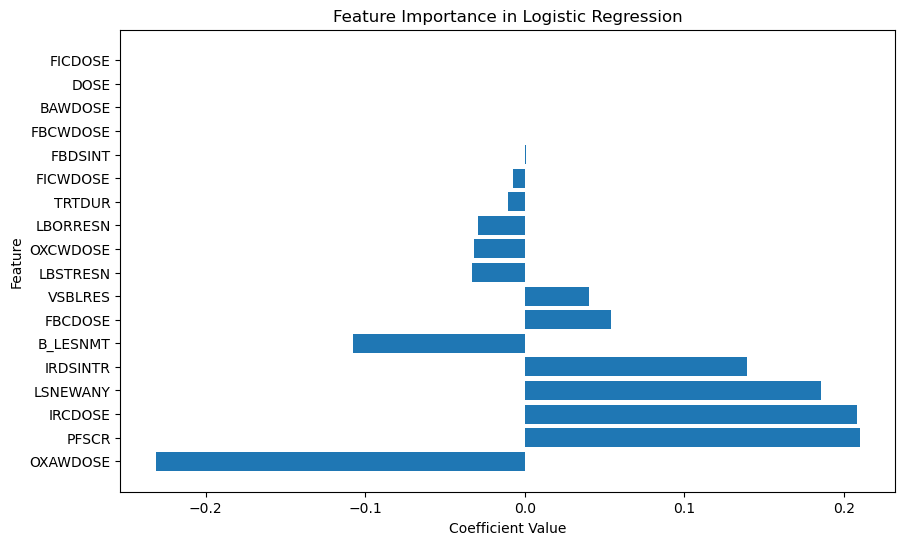

In [112]:
if len(best_model.coef_) == 1:
    coefficients = best_model.coef_[0]
else:
    coefficients = np.mean(best_model.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# XGBoost Regression

In [114]:
import xgboost as xgb

In [116]:
features=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
target=result1[['LSSLD_Change']]

In [118]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [120]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, target, test_size=0.2, random_state=42)

In [122]:
# Initialize and fit the XGBoost model
model12 = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model12.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [124]:
y_pred = model12.predict(X_test)

In [126]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.9862
Confusion Matrix:
[[214   3]
 [  0   1]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       217
           1       0.25      1.00      0.40         1

    accuracy                           0.99       218
   macro avg       0.62      0.99      0.70       218
weighted avg       1.00      0.99      0.99       218



# Regression with Linear,Decision Tree,Random Forest,Gadient Boosting,Support Vector and Neural Network

In [56]:
features=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
target=result1[['LSSLD_Change']]

In [57]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "Support Vector Regression": make_pipeline(StandardScaler(), SVR()),
    "Neural Network": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000))
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calculate Mean Squared Error and R² Score
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name} - Mean Squared Error: {mse}, R² Score: {r2}")


Linear Regression - Mean Squared Error: 0.0048014759842033026, R² Score: -0.051545367157961985
Decision Tree - Mean Squared Error: 0.028669724770642203, R² Score: -5.278801843317972
Random Forest - Mean Squared Error: 0.009000447034471282, R² Score: -0.9711393772636552
Gradient Boosting - Mean Squared Error: 0.012411359770251972, R² Score: -1.7181449848914965
Support Vector Regression - Mean Squared Error: 0.007087882925621732, R² Score: -0.5522790237661162
Neural Network - Mean Squared Error: 0.013197190003631476, R² Score: -1.8902454273390887


# ROC and AUC

In [58]:
X, y = make_classification(n_samples=1000, n_features=20, 
                           n_informative=2, n_redundant=10, 
                           random_state=42)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [59]:
# Train a model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict probabilities
y_score = model.predict_proba(X_test)[:, 1]

# Compute ROC curve and ROC AUC
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

In [60]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.84


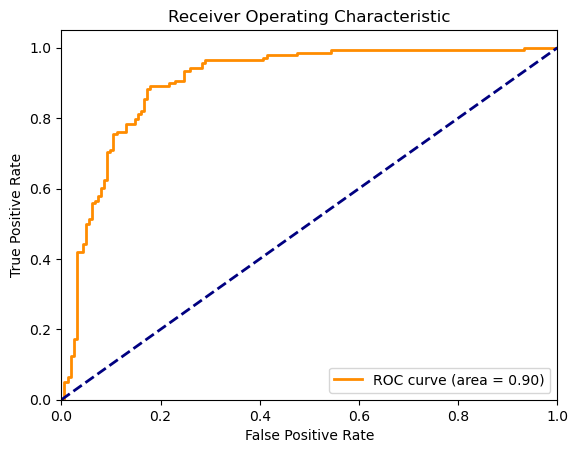

In [61]:
# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# KNN Model

In [63]:
X=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSSLD_Change']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [64]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

In [65]:
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [66]:
y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f'Accuracy: {accuracy}')
print('Confusion Matrix:')
print(conf_matrix)
print('Classification Report:')
print(class_report)

Accuracy: 0.9954128440366973
Confusion Matrix:
[[217   0]
 [  1   0]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       217
           1       0.00      0.00      0.00         1

    accuracy                           1.00       218
   macro avg       0.50      0.50      0.50       218
weighted avg       0.99      1.00      0.99       218



# Conclusion:

# Features Selected:
'LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR'

# Regression Models

# Logistic Regression: 
Accuracy: 0.9954
Confusion Matrix:

[[217   0]

 [  1   0]]


# Hyperparameter Tuning:
Test Accuracy: 0.9954

Confusion Matrix:

[[217   0]

 [  1   0]]

# Elastic Net

Cross-validation scores: [0.98857143 0.98857143 0.99425287 0.98850575 0.98850575]

Mean CV accuracy: 0.9897 (+/- 0.0023)

Confusion Matrix on Test Data:

[[217   0]

 [  1   0]]



# XGBoost Regression:
Accuracy: 0.9862
Confusion Matrix:

[[214   3]
 
[  0   1]]


# Linear Regression:
Mean Squared Error: 0.0048014759842033026
R² Score: -0.051545367157961985

# Decision Tree:
Mean Squared Error:  0.028669724770642203
R² Score: -5.278801843317972

# Random Forest:
Mean Squared Error: 0.009000447034471282
R² Score: -0.9711393772636552

# Gradient Boosting:
Mean Squared Error: 0.012411359770251972
R² Score: -1.7181449848914965R² 

# Support Vector Regression:
Mean Squared Error: 0.007087882925621732
R² Score: -0.5522790237661162

# Neural Network:
Mean Squared Error: 0.013197190003631476
R² Score: -1.8902454273390887

# ROC and AUC
Accuracy: 0.84

# KNN Classifier:
Acc

 # Summary:

Both Logistic Regression (with and without hyperparameter tuning) and KNN are the best models considering the confusion matrix and overall accuracy. They both have the highest accuracy (0.9954 for Logistic Regression and 0.9954128440366973 for KNN).Elastic Net also shows comparable performance with high cross-validation scores and similar confusion matrix results. uracy: 0.9954128440366973

Confusion Matrix:

[[217   0]

 [  1   0]]